# Autoregressive Word-Level Text Generation on Tiny Shakespeare
### Simple RNN vs Bidirectional RNN vs LSTM vs GRU

**Course:** Foundations of Generative AI (ICT4403) — Assignment 2

**Objective.** Build an autoregressive next-word text-generation system on a real text corpus, train four
recurrent architectures (Simple RNN, Bidirectional RNN, LSTM, GRU) under identical experimental conditions,
compare them quantitatively (loss, perplexity, accuracy, training time) and qualitatively (coherence,
diversity, contextual consistency, repetition), and study how the sampling temperature changes the
generated text.

**Pipeline**
1. Load and describe the dataset
2. Preprocess: normalise, tokenise into words + punctuation + line breaks, build the vocabulary
3. Build sliding-window input–target pairs `(w[t-20..t-1]) → w[t]`
4. Train the four models with the same embedding size, hidden size, optimiser, batch size, data and stopping rule
5. Evaluate on a held-out test split
6. Generate text from the same seeds at four temperatures and measure diversity / repetition / fluency
7. Compare and pick the best model

In [1]:
import os, re, json, time, random, collections, math
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import warnings; warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

DATA_PATH   = "data/tiny_shakespeare.txt"
DATA_URL    = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
RESULTS_DIR = "results"; PLOTS_DIR = "plots"; MODELS_DIR = "models"
for d in (RESULTS_DIR, PLOTS_DIR, MODELS_DIR, "data"):
    os.makedirs(d, exist_ok=True)

# ---- shared experimental configuration (identical for all four models) ----
CFG = dict(
    seq_len=20,        # context window (tokens)
    min_freq=3,        # words seen < 3 times -> <unk>
    embed_dim=128,
    hidden_units=256,  # units per recurrent layer (per direction for the BiRNN)
    dropout=0.2,
    batch_size=256,
    max_epochs=20,
    patience=3,        # early stopping on validation loss
    learning_rate=1e-3,
    clipnorm=1.0,
    split=(0.8, 0.1, 0.1),
)
MODEL_NAMES = ["SimpleRNN", "BiRNN", "LSTM", "GRU"]
COLORS = {"SimpleRNN": "#2a78d6", "BiRNN": "#eb6834", "LSTM": "#1baf7a", "GRU": "#eda100"}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.titleweight": "bold", "lines.linewidth": 2,
})
print("TensorFlow", tf.__version__, "| devices:", [d.device_type for d in tf.config.list_physical_devices()])

TensorFlow 2.21.0 | devices: ['CPU']


## 1. Dataset

**Tiny Shakespeare** (Andrej Karpathy, `char-rnn` repository) is a ~1.1 MB plain-text concatenation of
around 40,000 lines from several Shakespeare plays (e.g. *Coriolanus*, *Richard II/III*, *Romeo and Juliet*,
*The Winter's Tale*, *Henry VI*). It is laid out as a play script: a speaker name followed by a colon on its own
line, then that character's lines of verse or prose, with blank lines between speeches.

Source: <https://github.com/karpathy/char-rnn/blob/master/data/tinyshakespeare/input.txt>
(raw: <https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt>)

Why it suits this task: it is small enough to train four recurrent models on a CPU, but it has a large
vocabulary, archaic grammar, strong local structure (speaker tags, verse lines, punctuation), and long-range
consistency requirements (a speech stays on one topic and in one voice) — which separates the architectures well.

In [2]:
if not os.path.exists(DATA_PATH):
    import urllib.request
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

raw_text = open(DATA_PATH, encoding="utf-8").read()
lines = raw_text.split("\n")
speaker_lines = [l for l in lines if re.fullmatch(r"[A-Z][A-Za-z ']+:", l.strip())]

stats = {
    "characters": len(raw_text),
    "lines": len(lines),
    "non_empty_lines": sum(1 for l in lines if l.strip()),
    "whitespace_words": len(raw_text.split()),
    "speeches (speaker tags)": len(speaker_lines),
    "distinct speakers": len(set(s.strip() for s in speaker_lines)),
}
display(pd.Series(stats, name="value").to_frame())
print(raw_text[:400])

,value
characters,1115394
lines,40001
non_empty_lines,32777
whitespace_words,202651
speeches (speaker tags),7940
distinct speakers,1027


First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it 


## 2. Preprocessing

* **Lower-casing** — removes the capitalised/uncapitalised duplicates of the same word (`The`/`the`), roughly halving sparse word types.
* **Tokenisation** — a regex splits the text into
  words (keeping internal apostrophes such as `o'er`, `'tis` → `tis`, `i'll`), punctuation marks (`, . ! ? ; : ' -`),
  and an explicit line-break token `<nl>`. Keeping punctuation and `<nl>` lets the models learn the play-script layout
  (speaker tag → colon → line break → speech) so generated text can be printed in the original format.
* **Vocabulary** — tokens occurring fewer than `min_freq = 3` times are mapped to `<unk>`. This cuts the softmax size
  by ~60% while keeping ~97% of running tokens.
* **Split** — the token stream is split *contiguously* into 80% train / 10% validation / 10% test, so the test text
  comes from unseen scenes rather than overlapping windows of the training text.

In [3]:
TOKEN_RE = re.compile(r"<nl>|[a-z]+(?:'[a-z]+)*|[.,!?;:'\-]")

def tokenize(text):
    text = text.lower().replace("\n", " <nl> ")
    return TOKEN_RE.findall(text)

tokens = tokenize(raw_text)
n = len(tokens)
n_tr, n_va = int(CFG["split"][0] * n), int(CFG["split"][1] * n)
train_tok, val_tok, test_tok = tokens[:n_tr], tokens[n_tr:n_tr + n_va], tokens[n_tr + n_va:]

# vocabulary from the TRAIN split only (no test leakage)
counts = collections.Counter(train_tok)
itos = ["<unk>"] + [w for w, c in counts.most_common() if c >= CFG["min_freq"]]
stoi = {w: i for i, w in enumerate(itos)}
VOCAB = len(itos)
UNK = stoi["<unk>"]; NL = stoi["<nl>"]

encode = lambda toks: np.array([stoi.get(t, UNK) for t in toks], dtype=np.int32)
train_ids, val_ids, test_ids = encode(train_tok), encode(val_tok), encode(test_tok)

prep = {
    "total tokens": n, "distinct token types": len(set(tokens)),
    "vocabulary size (incl. <unk>)": VOCAB,
    "train / val / test tokens": f"{len(train_ids):,} / {len(val_ids):,} / {len(test_ids):,}",
    "<unk> rate train": f"{(train_ids == UNK).mean():.2%}",
    "<unk> rate test":  f"{(test_ids == UNK).mean():.2%}",
}
display(pd.Series(prep, name="value").to_frame())
print("Most frequent tokens:", counts.most_common(20))
print("Tokenised sample:", tokens[:30])

,value
total tokens,293562
distinct token types,12382
vocabulary size (incl. <unk>),4297
train / val / test tokens,"234,849 / 29,356 / 29,357"
<unk> rate train,3.56%
<unk> rate test,9.78%


Most frequent tokens: [('<nl>', 31626), (',', 15899), (':', 7994), ('.', 6119), ('the', 5195), ('and', 4518), ('to', 3947), ('i', 3607), ('of', 3194), (';', 2877), ('my', 2553), ('you', 2283), ('a', 2268), ('that', 2132), ('in', 1913), ('?', 1908), ('!', 1742), ('not', 1603), ('is', 1600), ('-', 1566)]
Tokenised sample: ['first', 'citizen', ':', '<nl>', 'before', 'we', 'proceed', 'any', 'further', ',', 'hear', 'me', 'speak', '.', '<nl>', '<nl>', 'all', ':', '<nl>', 'speak', ',', 'speak', '.', '<nl>', '<nl>', 'first', 'citizen', ':', '<nl>', 'you']


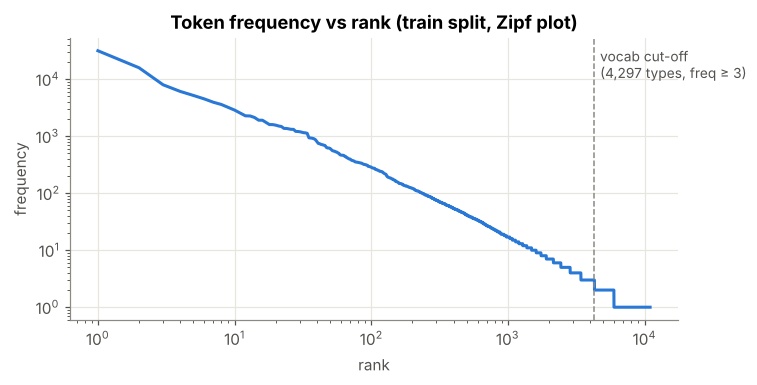

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6))
freqs = np.array(sorted(counts.values(), reverse=True))
ax.loglog(np.arange(1, len(freqs) + 1), freqs, color=COLORS["SimpleRNN"])
ax.axvline(VOCAB, color="#8a8984", ls="--", lw=1)
ax.text(VOCAB * 1.1, freqs.max() / 3, f"vocab cut-off\n({VOCAB:,} types, freq ≥ {CFG['min_freq']})", color="#52514e", fontsize=9)
ax.set_xlabel("rank"); ax.set_ylabel("frequency"); ax.set_title("Token frequency vs rank (train split, Zipf plot)")
plt.tight_layout(); plt.savefig(f"{PLOTS_DIR}/token_frequency_zipf.png"); plt.show()

### Constructing autoregressive input–target sequences

Autoregressive modelling factorises the probability of a text as
$P(w_1,\dots,w_T)=\prod_t P(w_t\mid w_{<t})$. We approximate the history with a fixed window of
`seq_len = 20` tokens and slide it one token at a time:

```
input  : w[t-20], w[t-19], ..., w[t-1]
target : w[t]
```

Every position of each split becomes one training example (stride 1). At generation time the predicted token is
appended to the window and the oldest token dropped, so the model feeds on its own output.

In [5]:
L = CFG["seq_len"]

def make_windows(ids, seq_len=L):
    X = np.lib.stride_tricks.sliding_window_view(ids[:-1], seq_len)
    y = ids[seq_len:]
    return np.ascontiguousarray(X), y

X_train, y_train = make_windows(train_ids)
X_val,   y_val   = make_windows(val_ids)
X_test,  y_test  = make_windows(test_ids)
print("X_train", X_train.shape, "y_train", y_train.shape)
print("X_val  ", X_val.shape,   "X_test ", X_test.shape)

def decode(ids): return " ".join(itos[i] for i in ids)
for k in (0, 7, 123):
    print(f"\n[{k}] input : {decode(X_train[k])}\n    target: {itos[y_train[k]]}")

X_train (234829, 20) y_train (234829,)
X_val   (29336, 20) X_test  (29337, 20)

[0] input : first citizen : <nl> before we proceed any further , hear me speak . <nl> <nl> all : <nl> speak
    target: ,

[7] input : any further , hear me speak . <nl> <nl> all : <nl> speak , speak . <nl> <nl> first citizen
    target: :

[123] input : <nl> <nl> second citizen : <nl> one word , good citizens . <nl> <nl> first citizen : <nl> we are
    target: <unk>


## 3. Models

All four models share the same skeleton — only the recurrent layer changes:

```
Embedding(VOCAB, 128) → <recurrent layer, 256 units> → Dropout(0.2) → Dense(VOCAB, softmax)
```

| Model | Recurrent layer | Idea |
|---|---|---|
| **Simple RNN** | `SimpleRNN(256)` | $h_t=\tanh(W x_t+U h_{t-1}+b)$. Cheapest; suffers from vanishing gradients over long contexts. |
| **Bidirectional RNN** | `Bidirectional(SimpleRNN(256))` | One SimpleRNN reads the 20-token window left→right, another right→left; final states are concatenated (512-d). **Only the context window is read in both directions — the target word is never visible**, so the model is still a valid autoregressive next-word predictor. |
| **LSTM** | `LSTM(256)` | Input, forget and output gates plus a cell state give an additive memory path that preserves gradients over long spans. |
| **GRU** | `GRU(256)` | Update and reset gates merge the LSTM's cell/hidden state; ~25% fewer recurrent parameters than an LSTM. |

**Comparable conditions:** same tokenisation, vocabulary, window length, data splits, embedding size, hidden units,
dropout, optimiser (Adam, lr = 1e-3, gradient clipping at norm 1.0), batch size (256), loss (sparse categorical
cross-entropy), maximum epochs (20), early stopping on validation loss (patience 3, best weights restored),
random seed, and hardware (CPU).

In [6]:
def build_model(kind, vocab=VOCAB, cfg=CFG):
    H = cfg["hidden_units"]
    rec = {
        "SimpleRNN": lambda: layers.SimpleRNN(H, name="simple_rnn"),
        "BiRNN":     lambda: layers.Bidirectional(layers.SimpleRNN(H), name="bidirectional_rnn"),
        "LSTM":      lambda: layers.LSTM(H, name="lstm"),
        "GRU":       lambda: layers.GRU(H, name="gru"),
    }[kind]
    model = keras.Sequential([
        keras.Input(shape=(cfg["seq_len"],), dtype="int32"),
        layers.Embedding(vocab, cfg["embed_dim"], name="embedding"),
        rec(),
        layers.Dropout(cfg["dropout"]),
        layers.Dense(vocab, activation="softmax", name="next_word"),
    ], name=kind)
    model.compile(
        optimizer=keras.optimizers.Adam(cfg["learning_rate"], clipnorm=cfg["clipnorm"]),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5")],
    )
    return model

param_counts = {}
for name in MODEL_NAMES:
    m = build_model(name)
    param_counts[name] = m.count_params()
    if name == "LSTM": m.summary()
pd.Series(param_counts, name="trainable parameters").to_frame()

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 20, 128)        │       550,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 256)            │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ next_word (Dense)               │ (None, 4297)           │     1,104,329 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,048,585 (7.81 MB)

 Trainable params: 2,048,585 (7.81 MB)

 Non-trainable params: 0 (0.00 B)

,trainable parameters
SimpleRNN,1752905
BiRNN,2951497
LSTM,2048585
GRU,1950793


## 4. Training

Each model is trained with the identical configuration above. Wall-clock time per epoch is recorded with a callback.
Trained weights and histories are cached in `models/` and `results/`, so re-running the notebook re-uses them
(delete `models/` to retrain from scratch).

In [7]:
class EpochTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None): self.times = []
    def on_epoch_begin(self, epoch, logs=None): self._t = time.perf_counter()
    def on_epoch_end(self, epoch, logs=None): self.times.append(time.perf_counter() - self._t)

models, histories, train_info = {}, {}, {}

for name in MODEL_NAMES:
    wpath, hpath = f"{MODELS_DIR}/{name}.weights.h5", f"{RESULTS_DIR}/history_{name}.json"
    tf.random.set_seed(SEED); np.random.seed(SEED); random.seed(SEED)
    model = build_model(name)
    if os.path.exists(wpath) and os.path.exists(hpath):
        model.load_weights(wpath)
        rec = json.load(open(hpath))
        print(f"{name}: loaded cached weights ({rec['epochs_run']} epochs, {rec['train_time_s']:.0f}s)")
    else:
        print(f"\n===== Training {name} =====")
        timer = EpochTimer()
        es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=CFG["patience"], restore_best_weights=True)
        t0 = time.perf_counter()
        h = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                      batch_size=CFG["batch_size"], epochs=CFG["max_epochs"],
                      callbacks=[es, timer], shuffle=True, verbose=2)
        total = time.perf_counter() - t0
        rec = {
            "history": {k: [float(v) for v in vals] for k, vals in h.history.items()},
            "epoch_times_s": timer.times,
            "epochs_run": len(timer.times),
            "best_epoch": int(np.argmin(h.history["val_loss"]) + 1),
            "train_time_s": total,
        }
        model.save_weights(wpath)
        json.dump(rec, open(hpath, "w"), indent=1)
    models[name], histories[name], train_info[name] = model, rec["history"], rec


===== Training SimpleRNN =====
Epoch 1/20


918/918 - 47s - 51ms/step - accuracy: 0.1985 - loss: 5.1587 - top5: 0.3424 - val_accuracy: 0.2473 - val_loss: 4.5342 - val_top5: 0.4038


Epoch 2/20


918/918 - 82s - 89ms/step - accuracy: 0.2484 - loss: 4.5183 - top5: 0.4097 - val_accuracy: 0.2598 - val_loss: 4.3212 - val_top5: 0.4341


Epoch 3/20


...

918/918 - 113s - 123ms/step - accuracy: 0.3018 - loss: 3.6797 - top5: 0.4983 - val_accuracy: 0.2832 - val_loss: 4.0889 - val_top5: 0.4793


Epoch 7/20


918/918 - 140s - 153ms/step - accuracy: 0.3105 - loss: 3.5480 - top5: 0.5133 - val_accuracy: 0.2816 - val_loss: 4.1177 - val_top5: 0.4779


Epoch 8/20


918/918 - 112s - 122ms/step - accuracy: 0.3194 - loss: 3.4259 - top5: 0.5289 - val_accuracy: 0.2812 - val_loss: 4.1522 - val_top5: 0.4742


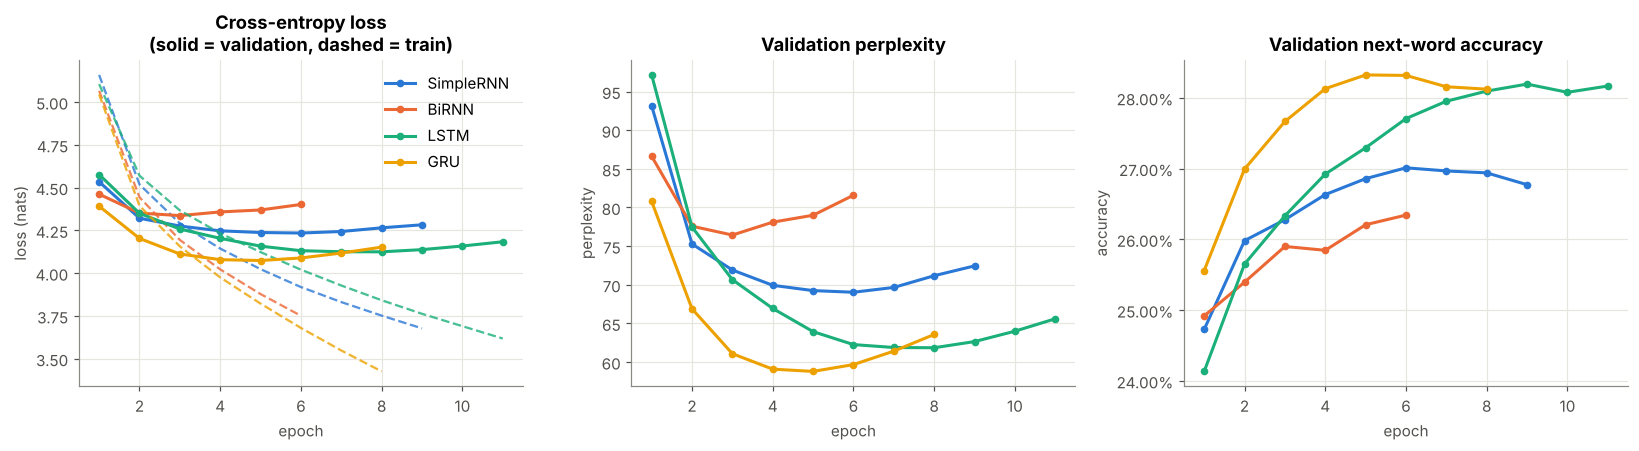

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for name in MODEL_NAMES:
    h = histories[name]; ep = np.arange(1, len(h["loss"]) + 1); c = COLORS[name]
    axes[0].plot(ep, h["loss"], color=c, ls="--", lw=1.5, alpha=0.8)
    axes[0].plot(ep, h["val_loss"], color=c, label=name, marker="o", ms=4)
    axes[1].plot(ep, np.exp(h["val_loss"]), color=c, label=name, marker="o", ms=4)
    axes[2].plot(ep, h["val_accuracy"], color=c, label=name, marker="o", ms=4)
axes[0].set_title("Cross-entropy loss\n(solid = validation, dashed = train)")
axes[1].set_title("Validation perplexity"); axes[2].set_title("Validation next-word accuracy")
for ax in axes: ax.set_xlabel("epoch")
axes[0].set_ylabel("loss (nats)"); axes[1].set_ylabel("perplexity"); axes[2].set_ylabel("accuracy")
axes[2].yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
axes[0].legend(frameon=False)
plt.tight_layout(); plt.savefig(f"{PLOTS_DIR}/training_curves.png"); plt.show()

## 5. Quantitative evaluation (held-out test split)

* **Loss** — mean cross-entropy (nats/token) of the true next word.
* **Perplexity** $=\exp(\text{loss})$ — the effective number of equally likely choices the model is torn between; lower is better.
* **Top-1 / Top-5 accuracy** — whether the true next word is the arg-max / among the 5 most probable predictions.
* **Training time** — total wall-clock time and mean time per epoch (same CPU for all models).

A **unigram baseline** (predicting from training-set word frequencies only, no context) is included as a sanity check.

In [9]:
rows = []
uni = np.bincount(train_ids, minlength=VOCAB) + 1.0; uni /= uni.sum()
uni_loss = float(-np.log(uni[y_test]).mean())
rows.append({"model": "Unigram baseline", "params": VOCAB, "test_loss": uni_loss, "test_perplexity": math.exp(uni_loss),
             "test_top1_acc": float((y_test == np.argmax(uni)).mean()),
             "test_top5_acc": float(np.isin(y_test, np.argsort(uni)[-5:]).mean()),
             "epochs_run": 0, "best_epoch": 0, "train_time_s": 0.0, "time_per_epoch_s": 0.0, "inference_ms_per_batch": 0.0})

for name in MODEL_NAMES:
    m = models[name]
    loss, acc, top5 = m.evaluate(X_test, y_test, batch_size=1024, verbose=0)
    xb = X_test[:256]; m.predict(xb, verbose=0)
    t0 = time.perf_counter()
    for _ in range(10): m(xb, training=False)
    infer = (time.perf_counter() - t0) / 10 * 1000
    ti = train_info[name]
    rows.append({"model": name, "params": param_counts[name], "test_loss": loss, "test_perplexity": math.exp(loss),
                 "test_top1_acc": acc, "test_top5_acc": top5, "epochs_run": ti["epochs_run"], "best_epoch": ti["best_epoch"],
                 "train_time_s": ti["train_time_s"], "time_per_epoch_s": float(np.mean(ti["epoch_times_s"])),
                 "inference_ms_per_batch": infer})

metrics = pd.DataFrame(rows).set_index("model")
metrics.to_csv(f"{RESULTS_DIR}/metrics.csv")
metrics.style.format({"params": "{:,.0f}", "test_loss": "{:.3f}", "test_perplexity": "{:.1f}",
                      "test_top1_acc": "{:.2%}", "test_top5_acc": "{:.2%}", "train_time_s": "{:.0f}",
                      "time_per_epoch_s": "{:.1f}", "inference_ms_per_batch": "{:.1f}"})

,params,test_loss,test_perplexity,test_top1_acc,test_top5_acc,epochs_run,best_epoch,train_time_s,time_per_epoch_s,inference_ms_per_batch
model,,,,,,,,,,
Unigram baseline,"4,297",5.053,156.5,14.76%,38.74%,0,0,0,0.0,0.0
SimpleRNN,"1,752,905",4.164,64.3,29.20%,47.43%,9,6,486,49.9,62.4
BiRNN,"2,951,497",4.199,66.6,28.32%,45.82%,6,3,450,75.0,111.7
LSTM,"2,048,585",4.038,56.7,30.39%,48.79%,11,8,1274,115.8,119.2
GRU,"1,950,793",4.035,56.6,30.61%,49.12%,8,5,964,120.5,144.8


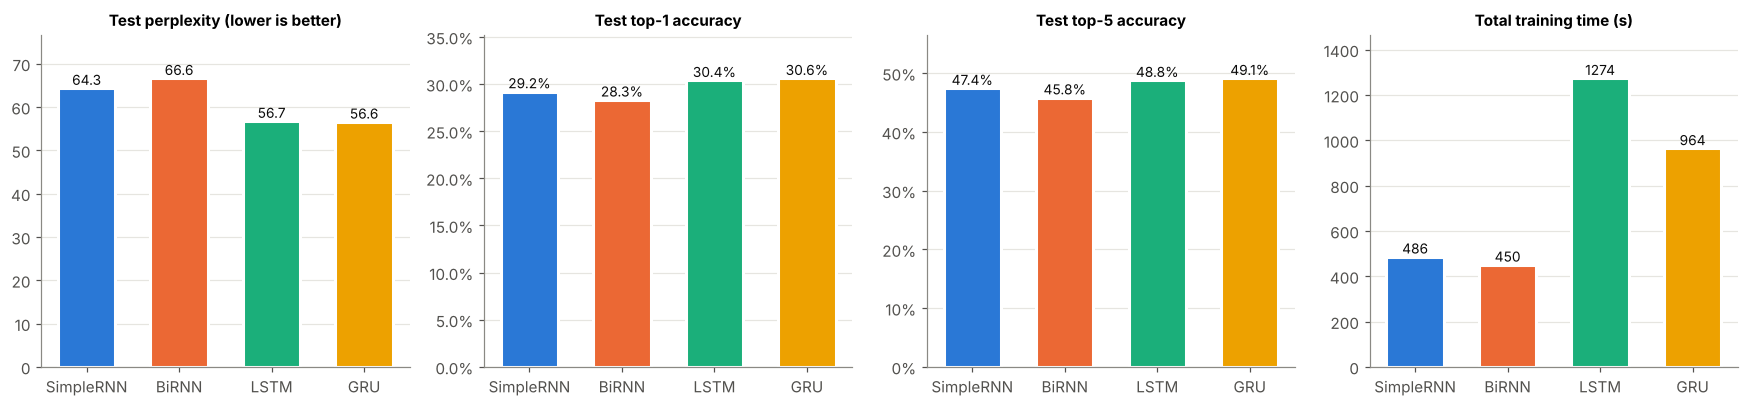

In [10]:
mm = metrics.loc[MODEL_NAMES]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
specs = [("test_perplexity", "Test perplexity (lower is better)", "{:.1f}"),
         ("test_top1_acc", "Test top-1 accuracy", "{:.1%}"),
         ("test_top5_acc", "Test top-5 accuracy", "{:.1%}"),
         ("train_time_s", "Total training time (s)", "{:.0f}")]
for ax, (col, title, fmt) in zip(axes, specs):
    vals = mm[col].values
    bars = ax.bar(MODEL_NAMES, vals, color=[COLORS[n] for n in MODEL_NAMES], width=0.62, edgecolor="white", linewidth=2)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v, fmt.format(v), ha="center", va="bottom", fontsize=9, color="#0b0b0b")
    ax.set_title(title, fontsize=10); ax.grid(axis="x", visible=False); ax.set_axisbelow(True)
    ax.set_ylim(0, vals.max() * 1.15)
    if col.endswith("acc"): ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
plt.tight_layout(); plt.savefig(f"{PLOTS_DIR}/test_metrics_comparison.png"); plt.show()

## 6. Autoregressive generation and sampling temperature

Generation loop: start from a 20-token seed window → predict $p(w_t\mid\text{window})$ → rescale with temperature
$T$ → sample → append the sampled token and slide the window → repeat for 60 tokens.

$$p_T(w)=\frac{\exp(\log p(w)/T)}{\sum_{w'}\exp(\log p(w')/T)}$$

* $T<1$ sharpens the distribution (safer, more repetitive), $T=1$ samples the model as trained, $T>1$ flattens it
  (more diverse, more errors). We use **T ∈ {0.2, 0.5, 1.0, 1.5}**.
* `<unk>` is masked out during sampling so the output contains only real words.
* **Seeds:** the same three 20-token passages taken from the *test* split (unseen during training), each starting at the beginning of a line of the script.
* For each (model, temperature) we draw 5 samples per seed (15 continuations) and compute:
  * **distinct-1 / distinct-2** — unique unigrams / bigrams ÷ total (higher = more diverse),
  * **repeated 3-gram rate** — share of 3-grams in a continuation that already occurred earlier in it (higher = more looping),
  * **novel 4-gram rate** — share of generated 4-grams that never appear in the training text (0 = copying, very high = incoherent),
  * **fluency proxy** — perplexity of the continuation under an independent add-k smoothed *bigram* model fitted on the
    training text (lower = locally more Shakespeare-like word transitions). It is a neutral judge that none of the four networks influences.

In [11]:
# ---- seeds: three 20-token windows from the unseen test text, each beginning at the start of a script line ----
def find_seed_starts(ids, k=3, gap=2500, max_unk=0):
    # speaker-tag windows; the test split is mostly a play (The Taming of the Shrew) whose character names
    # are unseen in training, so windows free of <unk> are rarer -> relax only if needed
    starts, i = [], 200
    while len(starts) < k and i < len(ids) - L - 5:
        is_tag = any(ids[i + j] == stoi[":"] and ids[i + j + 1] == NL for j in (1, 2, 3))
        if ids[i - 1] == NL and ids[i] != NL and is_tag and (ids[i:i + L] == UNK).sum() <= max_unk:
            starts.append(i); i += gap
        i += 1
    return starts if len(starts) == k or max_unk > 2 else find_seed_starts(ids, k, gap, max_unk + 1)

seed_starts = find_seed_starts(test_ids)
SEEDS = [test_ids[s:s + L] for s in seed_starts]

PUNCT_NOSPACE = set(".,!?;:")
def detok(ids):
    out = ""
    for i in ids:
        w = itos[i]
        if w == "<nl>": out = out.rstrip(" ") + "\n"
        elif w in PUNCT_NOSPACE or w == "'": out = out.rstrip(" ") + w + " "
        else: out += w + " "
    return out.strip()

for k, s in enumerate(SEEDS): print(f"--- seed {k+1} ---\n{detok(s)}\n")

--- seed 1 ---
vincentio:
fair sir, and you my merry mistress,
that with your strange encounter much amazed

--- seed 2 ---
widow:
lord, let me never have a cause to sigh,
till i be brought to

--- seed 3 ---
now i arise:
sit still, and hear the last of our sea - sorrow.
here



In [12]:
def generate(model, seed_ids, n_tokens=60, temperature=1.0, n_samples=1, rng=None):
    rng = rng or np.random.default_rng(SEED)
    win = np.tile(np.asarray(seed_ids, dtype=np.int32), (n_samples, 1))
    out = []
    for _ in range(n_tokens):
        p = model(win, training=False).numpy().astype(np.float64)
        p[:, UNK] = 0.0
        logp = np.log(p + 1e-12) / temperature
        logp -= logp.max(axis=1, keepdims=True)
        q = np.exp(logp); q /= q.sum(axis=1, keepdims=True)
        nxt = np.array([rng.choice(VOCAB, p=qi) for qi in q], dtype=np.int32)
        out.append(nxt)
        win = np.concatenate([win[:, 1:], nxt[:, None]], axis=1)
    return np.stack(out, axis=1)  # (n_samples, n_tokens)

# ---- independent bigram judge (add-k smoothing) fitted on the training split ----
K_SMOOTH = 0.1
big = collections.Counter(zip(train_ids[:-1], train_ids[1:]))
uni_c = np.bincount(train_ids, minlength=VOCAB).astype(np.float64)
def bigram_ppl(prev_last, ids):
    seq = [prev_last] + list(ids); lp = 0.0
    for a, b in zip(seq[:-1], seq[1:]):
        lp += math.log((big.get((a, b), 0) + K_SMOOTH) / (uni_c[a] + K_SMOOTH * VOCAB))
    return math.exp(-lp / len(ids))

train_4grams = set(zip(train_ids[:-3], train_ids[1:-2], train_ids[2:-1], train_ids[3:]))

def ngrams(seq, n): return list(zip(*[seq[i:] for i in range(n)]))
def text_metrics(seed, cont):
    cont = list(cont)
    tri = ngrams(cont, 3); four = ngrams(cont, 4)
    seen, rep = set(), 0
    for t in tri:
        rep += t in seen; seen.add(t)
    return {"distinct1": len(set(cont)) / len(cont),
            "distinct2": len(set(ngrams(cont, 2))) / max(1, len(cont) - 1),
            "rep3": rep / max(1, len(tri)),
            "novel4": sum(f not in train_4grams for f in four) / max(1, len(four)),
            "judge_ppl": bigram_ppl(seed[-1], cont)}

# reference values for real (human) Shakespeare continuations of the same length from the test split
ref = [text_metrics(test_ids[s:s+L], test_ids[s+L:s+L+60]) for s in range(500, len(test_ids) - 100, 997)]
human_ref = pd.DataFrame(ref).mean().rename("Human (test text)")
human_ref

distinct1      0.595977
distinct2      0.888369
rep3           0.052913
novel4         0.788264
judge_ppl    193.652437
Name: Human (test text), dtype: float64

In [13]:
TEMPS = [0.2, 0.5, 1.0, 1.5]
N_TOK, N_SAMP = 60, 5
gen_rows, examples = [], {}
for name in MODEL_NAMES:
    for T in TEMPS:
        rng = np.random.default_rng(SEED)
        for si, seed in enumerate(SEEDS):
            conts = generate(models[name], seed, N_TOK, T, N_SAMP, rng)
            examples[(name, T, si)] = conts[0]
            for c in conts:
                gen_rows.append({"model": name, "temperature": T, "seed": si + 1, **text_metrics(seed, c)})

gen = pd.DataFrame(gen_rows)
gen_summary = gen.groupby(["model", "temperature"])[["distinct1", "distinct2", "rep3", "novel4", "judge_ppl"]].mean()
gen_summary = gen_summary.reindex(pd.MultiIndex.from_product([MODEL_NAMES, TEMPS], names=["model", "temperature"]))
gen_summary.to_csv(f"{RESULTS_DIR}/generation_metrics.csv")
gen_summary.style.format("{:.3f}").format({"judge_ppl": "{:.0f}"})

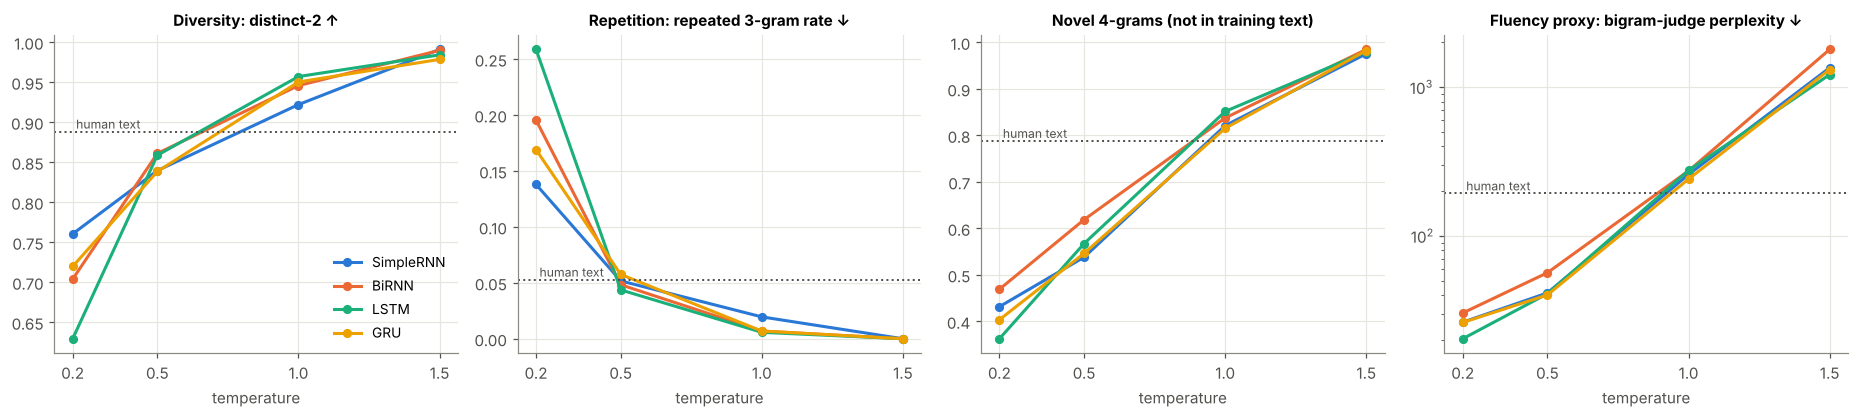

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.9))
specs = [("distinct2", "Diversity: distinct-2 ↑"), ("rep3", "Repetition: repeated 3-gram rate ↓"),
         ("novel4", "Novel 4-grams (not in training text)"), ("judge_ppl", "Fluency proxy: bigram-judge perplexity ↓")]
for ax, (col, title) in zip(axes, specs):
    for name in MODEL_NAMES:
        ax.plot(TEMPS, gen_summary.loc[name, col].values, marker="o", ms=5, color=COLORS[name], label=name)
    ax.axhline(human_ref[col], color="#52514e", ls=":", lw=1.3)
    ax.text(TEMPS[0], human_ref[col], " human text", va="bottom", fontsize=8, color="#52514e")
    ax.set_title(title, fontsize=10); ax.set_xlabel("temperature"); ax.set_xticks(TEMPS)
axes[3].set_yscale("log")
axes[0].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.savefig(f"{PLOTS_DIR}/temperature_effects.png"); plt.show()

In [15]:
# ---- write every generated sample to a markdown file and print seed 1 for all models/temperatures ----
with open(f"{RESULTS_DIR}/generated_samples.md", "w") as f:
    f.write("# Generated text samples\n\nEach continuation is 60 tokens, generated autoregressively from the same 20-token seed "
            "(taken from the unseen test split). `<unk>` is masked during sampling. First sample of each (model, temperature, seed) shown.\n\n")
    for si, seed in enumerate(SEEDS):
        f.write(f"## Seed {si+1}\n\n```text\n{detok(seed)}\n```\n\n")
        for name in MODEL_NAMES:
            f.write(f"### {name}\n\n")
            for T in TEMPS:
                f.write(f"**T = {T}**\n\n```text\n{detok(examples[(name, T, si)])}\n```\n\n")

si = 0
print("SEED:\n" + detok(SEEDS[si]) + "\n" + "=" * 80)
for name in MODEL_NAMES:
    for T in TEMPS:
        print(f"\n### {name} | T = {T}\n{detok(examples[(name, T, si)])}")
    print("-" * 80)

SEED:
vincentio:
fair sir, and you my merry mistress,
that with your strange encounter much amazed

### SimpleRNN | T = 0.2
.

king richard ii:
i am not, that i am not to the world.

king richard ii:
the duke of norfolk, and my lord,
and all the world of his pernicious bed,
that he hath been a little man,
and in the world

### SimpleRNN | T = 0.5
.

king richard iii:
it is the matter, my lord, my lord,
which he hath been a thing.

menenius:
i do not, sir, sir, that i am it.

mercutio:
if it not,
i have not been with

### SimpleRNN | T = 1.0
. his mother,
i mean, what early thy warlike father's hate,
one that that use sits soon in sign of blood,
as he cannot hide the hearts and the wisest;
and bid not kiss him. there's the price is authority,
and this and power, he less commands

### SimpleRNN | T = 1.5
more verge.
strange know she is rivers into a hinder houses;
one deadly us not lived griefs again; fresh ends o,
go by rosaline here to lay his love beg? duty, awhile, throne - till inte

In [16]:
for si in (1, 2):
    print("\nSEED:\n" + detok(SEEDS[si]) + "\n" + "=" * 80)
    for name in MODEL_NAMES:
        print(f"\n### {name} | T = 0.5\n{detok(examples[(name, 0.5, si)])}")


SEED:
widow:
lord, let me never have a cause to sigh,
till i be brought to

### SimpleRNN | T = 0.5
him, and you must not.

gloucester:
ay, for the world be it.

angelo:
ay, i beseech you,
my lord, i warrant, my lord.

first watchman:
your husband's own the crown, my lord,
and whom i

### BiRNN | T = 0.5
this.

mercutio:
o, let me go; and thou be too dead.

duke of york:
take my husband's father's:
my lord, i do not with a light;
and they will live and northumberland,
and i will not him the duke of york

### LSTM | T = 0.5
see my soul, for it,
and if it be thee, i will not laugh.

second murderer:
o, i must not, and that not have it,
that you are full of a end: i will confess
to - - i will not what is so,

### GRU | T = 0.5
see my wife, but you,
and all my soul will be this of my joys.

duke of york:
where is you that, my lord?

york:
what is it, i should not say to fight.

king richard iii:
o, my

SEED:
now i arise:
sit still, and hear the last of our sea - sorrow.
here

### SimpleRN

## 7. Overall comparison

In [17]:
best_T = {}
summary = metrics.loc[MODEL_NAMES, ["test_perplexity", "test_top1_acc", "test_top5_acc", "train_time_s", "params"]].copy()
for name in MODEL_NAMES:
    g = gen_summary.loc[name]
    summary.loc[name, "distinct2@T=0.5"] = g.loc[0.5, "distinct2"]
    summary.loc[name, "rep3@T=0.5"] = g.loc[0.5, "rep3"]
    summary.loc[name, "judge_ppl@T=0.5"] = g.loc[0.5, "judge_ppl"]
    summary.loc[name, "judge_ppl@T=1.0"] = g.loc[1.0, "judge_ppl"]
summary["rank_perplexity"] = summary["test_perplexity"].rank()
summary.to_csv(f"{RESULTS_DIR}/overall_summary.csv")
print("Best model by test perplexity:", summary["test_perplexity"].idxmin())
summary.style.format({"test_perplexity": "{:.1f}", "test_top1_acc": "{:.2%}", "test_top5_acc": "{:.2%}",
                      "train_time_s": "{:.0f}", "params": "{:,.0f}", "distinct2@T=0.5": "{:.3f}",
                      "rep3@T=0.5": "{:.3f}", "judge_ppl@T=0.5": "{:.0f}", "judge_ppl@T=1.0": "{:.0f}",
                      "rank_perplexity": "{:.0f}"})

Best model by test perplexity: GRU


,test_perplexity,test_top1_acc,test_top5_acc,train_time_s,params,distinct2@T=0.5,rep3@T=0.5,judge_ppl@T=0.5,judge_ppl@T=1.0,rank_perplexity
model,,,,,,,,,,
SimpleRNN,64.3,29.20%,47.43%,486,"1,752,905",0.840,0.052,41,259,3
BiRNN,66.6,28.32%,45.82%,450,"2,951,497",0.861,0.048,57,274,4
LSTM,56.7,30.39%,48.79%,1274,"2,048,585",0.859,0.044,41,276,2
GRU,56.6,30.61%,49.12%,964,"1,950,793",0.838,0.057,40,242,1


## 8. Analysis and conclusion

### 8.1 Quantitative comparison

| Model | Params | Test loss | Test perplexity ↓ | Top-1 acc ↑ | Top-5 acc ↑ | Epochs (best) | Time / epoch | Total training time |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Unigram baseline (no context) | – | 5.053 | 156.5 | 14.76% | 38.74% | – | – | – |
| Simple RNN | 1.75 M | 4.164 | 64.3 | 29.20% | 47.43% | 9 (6) | 50 s | 486 s |
| Bidirectional RNN | 2.95 M | 4.199 | 66.6 | 28.32% | 45.82% | 6 (3) | 75 s | 450 s |
| LSTM | 2.05 M | 4.038 | 56.7 | 30.39% | 48.79% | 11 (8) | 116 s | 1274 s |
| **GRU** | 1.95 M | **4.035** | **56.6** | **30.61%** | **49.12%** | 8 (5) | 120 s | 964 s |

* **All four models learn real context.** Every network cuts perplexity from 156.5 (unigram) to 57–67 and doubles
  top-1 accuracy (14.8% → 28–31%).
* **Gated models win clearly.** LSTM and GRU reach ≈ 56.6 perplexity, ~12% lower than the Simple RNN (64.3) and
  ~15% lower than the Bidirectional RNN (66.6). Their gates keep useful information from the whole 20-token window,
  whereas the plain RNN's state is dominated by the last few words.
* **GRU vs LSTM is essentially a tie on accuracy** (56.6 vs 56.7 perplexity, 30.6% vs 30.4% top-1 — within run-to-run
  noise), but the GRU has 5% fewer parameters, reaches its best validation loss after 5 epochs instead of 8, and needed
  **24% less total training time** (964 s vs 1274 s). Per epoch the two cost about the same on this CPU.
* **Bidirectionality does not help next-word prediction.** Despite having the most parameters, the BiRNN is the worst
  model. Reading the context window backwards adds no information about the *next* word (the most predictive tokens
  are the most recent ones, which the forward pass already sees last) but adds 1.2 M parameters, so the model overfits
  fastest — validation loss is lowest at epoch 3 and rises afterwards. It is also the slowest Simple-RNN variant per epoch
  (75 s vs 50 s). Note also that a bidirectional model cannot reuse its state incrementally during generation: the whole
  window must be re-read backwards for every new token.
* **Overfitting is the limiting factor for all models.** The training curves show training loss falling steadily while
  validation loss turns upward after 3–8 epochs; ~235 k training tokens is small for 2 M-parameter models, so early
  stopping with best-weight restoration is essential.
* **The test split measures generalisation to unseen text:** it is mostly a play not present in training (*The Taming
  of the Shrew*), so 9.8% of its tokens are `<unk>` (3.6% in training) and its character names are unknown to the models.
  Because `<unk>` is a single shared class it is comparatively easy to predict, so the absolute perplexities should only
  be compared within this study, not with other papers.

### 8.2 Effect of sampling temperature

Averages over 15 continuations (3 seeds × 5 samples, 60 tokens each). "Human" = real 60-token continuations from the test text.

| T | distinct-2 ↑ | repeated 3-grams ↓ | novel 4-grams | bigram-judge perplexity ↓ |
|---|---|---|---|---|
| 0.2 | 0.63 – 0.76 | 0.14 – 0.26 | 0.36 – 0.47 | 20 – 30 |
| 0.5 | 0.84 – 0.86 | 0.04 – 0.06 | 0.54 – 0.62 | 40 – 57 |
| 1.0 | 0.92 – 0.96 | 0.01 – 0.02 | 0.82 – 0.85 | 242 – 276 |
| 1.5 | 0.98 – 0.99 | 0.00 | 0.98 | 1216 – 1795 |
| *Human text* | *0.89* | *0.05* | *0.79* | *194* |

* **Low temperature (T = 0.2) — coherent locally, but repetitive and generic.** Sampling is almost greedy, so every model
  falls into high-frequency loops: *"my lord, my lord, my lord"*, *"and i will not … and i will not"*,
  *"the king of york, … the duke of york"*. Repeated-3-gram rates (0.14–0.26) are 3–5× higher than in real text and
  diversity is the lowest. The very low judge perplexity (20–30, far below human 194) shows the text is *too* predictable
  — safe, common word transitions rather than Shakespearean variety. The LSTM is the most repetitive here (0.26).
* **Moderate temperature (T = 0.5) — the most readable output.** Repetition drops to human level (≈ 0.05), the play
  format is respected (speaker tag → colon → new line → speech), lines are mostly grammatical
  (*"and, if thou wilt not speak to me, / and i am so, and i be bound to fight"* — LSTM), but content is still somewhat
  bland and diversity slightly below human text.
* **T = 1.0 — closest to real-text statistics, less coherent.** Diversity (0.92–0.96) and novelty (0.82–0.85) are just
  above human values and repetition disappears. Vocabulary becomes rich and archaic (*"fair saint of all"*, *"a prosperous
  youth"*), but grammar breaks more often and sentences lose their thread after a few words.
* **High temperature (T = 1.5) — diverse but incoherent.** Almost every 4-gram is new, repetition is zero, and the judge
  perplexity explodes (> 1200): word salad such as *"knees in encounter by men richard's power! before with him receive the
  better scene"*. Speaker tags largely disappear, i.e. the models lose the document structure.
* **Trade-off.** Increasing temperature monotonically trades coherence for diversity: repetition ↓, diversity ↑,
  novelty ↑, fluency ↓. For this dataset **T ≈ 0.5–0.7** gives the best balance of readable, non-repetitive text;
  **T = 1.0** matches the diversity of real Shakespeare but at a clear cost in coherence.

**Model differences in generation.** At T = 0.5 the GRU (judge perplexity 40.2) and LSTM (40.9) produce the most fluent
text, the Simple RNN is close (41.5) and the BiRNN is clearly worst (56.7), mirroring the test-perplexity ranking. At
T = 1.0 the GRU has the lowest judge perplexity (242, closest to the human 194) — it stays more fluent than the other
models while being equally diverse. The gated models also hold the speaker/speech structure better over 60 tokens.

**Contextual consistency.** None of the models carries the seed's specific context forward for long: with a 20-token
window and seeds from an unseen play (characters such as Vincentio or the Widow are `<unk>` to the models), all
continuations drift back to the characters and themes of the training plays (Richard, York, Norfolk, Romeo, Menenius).
Topic consistency holds for roughly one line; style, register and layout are maintained much longer.

### 8.3 Conclusion

**The GRU is the most effective autoregressive generator for Tiny Shakespeare.** It achieves the lowest test perplexity
(56.6) and the highest top-1 (30.6%) and top-5 (49.1%) accuracy, produces the most fluent text at both T = 0.5 and
T = 1.0, and trains 24% faster than the LSTM with fewer parameters. The LSTM is a very close second in accuracy (the
difference is within the noise of a single run) but costs more training time. The Simple RNN is fast but measurably
weaker, and the Bidirectional RNN is the least suitable: bidirectional reading of the context gives no benefit for
predicting the next word and only adds parameters and overfitting. For generation, a temperature around 0.5–0.7 gives
the best balance between coherence and diversity.

**Limitations and possible improvements:** single training run per model (no seed averaging); a 20-token window limits
long-range consistency; stronger regularisation (higher dropout, weight tying between embedding and output layer),
stacked recurrent layers, or top-k / nucleus sampling would likely improve generation quality further.